# 08 — Capped LSTM, CNN, RNN and GRU (FD001)

**Question:** which neural network reads the raw sensor history best, and why?

**Problem type:** supervised **regression** on multivariate time series. The label (RUL = last cycle − current cycle) comes from run-to-failure data, and the answer is a number of cycles. The 125-cycle line only splits the *reporting* into early points (true RUL > 125) and late points (true RUL ≤ 125).

**Models in this notebook**

| Model | One-line reason it is here |
| --- | --- |
| Capped LSTM | Main model for engines near failure. Trained on RUL capped at 125, so it focuses on the part where sensors change |
| 1D CNN | A non-recurrent alternative: filters slide along time and look for local patterns |
| Plain RNN | Control with **no gates**: shows what memory gates add |
| GRU | 2 gates: the lighter gated model |
| LSTM | 3 gates plus a memory cell: the model we chose |

**Metrics** (project-wide policy): MAE and RMSE (headline), R², early and late RMSE (supporting), late precision and recall (secondary: they describe one yes/no decision, "close to failure?"). Every metric is computed **per seed**, then averaged. Models are chosen on **validation only**. Test labels are not loaded here.

In [1]:
import sys, time
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
import train as T
from evaluation import CUTOFFS
from models_lstm import LSTMRegressor
from models_cnn import CNNRegressor
from models_rnn_gru import RecurrentRegressor

SEEDS_EXP = [0, 1, 2]          # validation-only experiments
SEEDS_FINAL = [0, 1, 2, 3, 4]  # final models
RESULTS = "../results"
LATE = 125

y_val = T.val_rul()
print("early-stopping engines:", [int(e) for e in T._data()["es_engines"]])
print("validation points:", len(y_val), " early:", int((y_val > LATE).sum()), " late:", int((y_val <= LATE).sum()))


def score_full(y, p):
    """All metrics for one seed. 'Late' (true RUL <= 125) is the positive class for precision and recall."""
    y, p = np.asarray(y), np.asarray(p)
    out = T.score_bands(y, p)                       # mae, rmse, early_rmse, late_rmse
    out["r2"] = r2_score(y, p)
    late, pred_late = y <= LATE, p <= LATE
    tp, fp, fn = (late & pred_late).sum(), (~late & pred_late).sum(), (late & ~pred_late).sum()
    out["late_precision"] = tp / max(tp + fp, 1)
    out["late_recall"] = tp / max(tp + fn, 1)
    return out


def summarise_full(val_preds):
    """Score each seed, then the mean over seeds (RMSE std = numpy default, ddof 0)."""
    df = pd.DataFrame([score_full(y_val, p) for p in val_preds])
    row = df.mean().to_dict()
    row["rmse_std"] = df["rmse"].std(ddof=0)
    return row


def write_preds(name, val, test):
    """Write the two contract files for one model (arrays are seeds x 100, in cycles)."""
    cols = [f"seed_{s}" for s in SEEDS_FINAL]
    v = pd.DataFrame(val.T, columns=cols)
    v.insert(0, "cycle", CUTOFFS["cycle"].values)
    v.insert(0, "engine_id", CUTOFFS["engine_id"].values)
    t = pd.DataFrame(test.T, columns=cols)
    t.insert(0, "engine_id", T.test_engine_ids())
    v.to_csv(f"{RESULTS}/val_predictions_{name}.csv", index=False)
    t.to_csv(f"{RESULTS}/test_predictions_{name}.csv", index=False)
    print(f"wrote {name}: val {v.shape}, test {t.shape}")

early-stopping engines: [2, 3, 6, 16, 23, 26, 40, 44, 51, 57, 58, 67, 71, 75, 88, 97]
validation points: 100  early: 22  late: 78


## 1. What capping does

For one training engine: the true RUL falls to 0, while the capped target stays flat at 125 until the engine is within 125 cycles of failure. The model is only asked to learn the part where the sensors actually change. Scoring still uses the **true** RUL.

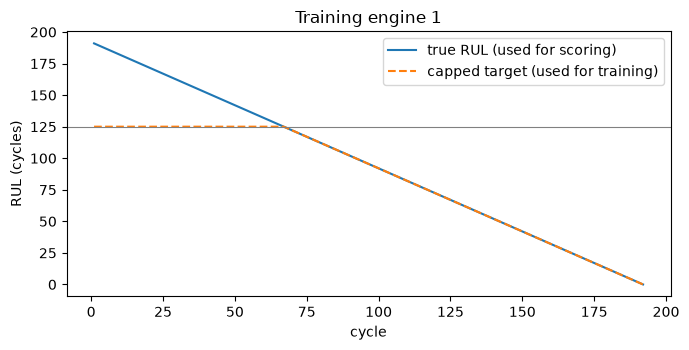

In [2]:
engine = int(sorted(T._data()["fit_engines"])[0])
rul = T._data()["rul"][engine]
cycles = np.arange(1, len(rul) + 1)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(cycles, rul, label="true RUL (used for scoring)")
ax.plot(cycles, np.minimum(rul, LATE), label="capped target (used for training)", linestyle="--")
ax.axhline(LATE, color="grey", linewidth=0.8)
ax.set_xlabel("cycle"); ax.set_ylabel("RUL (cycles)"); ax.set_title(f"Training engine {engine}")
ax.legend(); plt.tight_layout(); plt.show()

## 2. Window length for the capped LSTM (3 seeds, validation)

Capped LSTM, 1 layer × 64, lr 0.001, window W = 30 / 50 / 70. Late RMSE is the number that matters for this model: near failure, a longer view of the decline should help.

In [3]:
rows = []
for W in (30, 50, 70):
    print(f"capped LSTM, W = {W}")
    val, _ = T.run_seeds(lambda: LSTMRegressor(units=64, layers=1), W, SEEDS_EXP, cap=125, lr=1e-3)
    rows.append(T.summarise(val, f"cap125 W{W} 1x64 lr0.001"))
window = pd.DataFrame(rows)
window.to_csv(f"{RESULTS}/experiments_capped_window.csv", index=False)
window.round(2)

capped LSTM, W = 30


  seed 0: 21 epochs, 13 s, val RMSE 39.42


  seed 1: 30 epochs, 19 s, val RMSE 39.69


  seed 2: 28 epochs, 17 s, val RMSE 39.02
capped LSTM, W = 50


  seed 0: 23 epochs, 23 s, val RMSE 39.76


  seed 1: 43 epochs, 43 s, val RMSE 39.64


  seed 2: 27 epochs, 27 s, val RMSE 41.55
capped LSTM, W = 70


  seed 0: 21 epochs, 29 s, val RMSE 40.36


  seed 1: 25 epochs, 35 s, val RMSE 40.20


  seed 2: 28 epochs, 37 s, val RMSE 39.43


,setting,rmse_mean,rmse_std,late_rmse_mean,late_rmse_std,early_rmse_mean
0,cap125 W30 1x64 lr0.001,39.38,0.28,15.69,0.15,78.58
1,cap125 W50 1x64 lr0.001,40.32,0.87,13.95,1.76,81.78
2,cap125 W70 1x64 lr0.001,40.00,0.40,12.23,0.30,82.10


## 3. Final capped LSTM (5 seeds)

W = 70, 1 layer × 64, lr 0.003, cap 125. This writes the prediction files that the two-stage hybrid needs.

In [4]:
print("capped LSTM, W = 70")
val_lc, test_lc = T.run_seeds(lambda: LSTMRegressor(units=64, layers=1), 70, SEEDS_FINAL, cap=125, lr=3e-3)
write_preds("lstm_capped", val_lc, test_lc)

capped LSTM, W = 70


  seed 0: 18 epochs, 25 s, val RMSE 39.49


  seed 1: 19 epochs, 51 s, val RMSE 40.61


  seed 2: 18 epochs, 24 s, val RMSE 40.19


  seed 3: 23 epochs, 30 s, val RMSE 39.46


  seed 4: 20 epochs, 26 s, val RMSE 39.18
wrote lstm_capped: val (100, 7), test (100, 6)


## 4. 1D CNN (5 seeds)

**Why a CNN on sensor data?** A CNN is not an image model. It is a *local-pattern detector with shared weights*, and it works on any grid. An image is a 2D grid with 3 colour channels. Our window is a **1D grid (time) with 14 channels (sensors)**. Each filter slides along time only (5 cycles at a time) and learns a pattern such as "sensor 4 rising fast". Neighbouring cycles are related, as neighbouring pixels are. The order of the sensor columns means nothing, so a 2D "image" CNN would be wrong.

The network ends in flatten → dense, so it knows *when* in the window a pattern happened. An earlier version with global average pooling lost that and did worst.

Uncapped W = 30 and capped W = 70, both lr 0.001.

In [5]:
print("CNN uncapped, W = 30")
val_cu, test_cu = T.run_seeds(lambda: CNNRegressor(W=30), 30, SEEDS_FINAL, cap=None, lr=1e-3)
write_preds("cnn_uncapped", val_cu, test_cu)
print("CNN capped, W = 70")
val_cc, test_cc = T.run_seeds(lambda: CNNRegressor(W=70), 70, SEEDS_FINAL, cap=125, lr=1e-3)
write_preds("cnn_capped", val_cc, test_cc)

CNN uncapped, W = 30


  seed 0: 21 epochs, 58 s, val RMSE 39.07


  seed 1: 18 epochs, 36 s, val RMSE 38.71


  seed 2: 17 epochs, 32 s, val RMSE 41.74


  seed 3: 18 epochs, 34 s, val RMSE 42.22


  seed 4: 19 epochs, 77 s, val RMSE 38.95
wrote cnn_uncapped: val (100, 7), test (100, 6)
CNN capped, W = 70


  seed 0: 21 epochs, 83 s, val RMSE 42.36


  seed 1: 22 epochs, 84 s, val RMSE 41.24


  seed 2: 20 epochs, 69 s, val RMSE 40.48


  seed 3: 48 epochs, 200 s, val RMSE 43.11


  seed 4: 17 epochs, 67 s, val RMSE 42.94
wrote cnn_capped: val (100, 7), test (100, 6)


## 5. Memory ladder: RNN → GRU → LSTM (3 seeds, validation)

**Why compare them?** All three read the window one cycle at a time and keep a memory. They differ in how well they control it:

- **RNN** has no gates. Its memory is overwritten at every step, so information from early in a 30–70 cycle window fades (the *vanishing gradient* problem).
- **GRU** adds 2 gates (update, reset) that decide what to keep.
- **LSTM** has 3 gates plus a separate memory cell.

Same settings as the chosen LSTMs, so only the cell changes: uncapped W = 30, 2 × 64, lr 0.001; capped W = 70, 1 × 64, lr 0.003. These settings were tuned for the LSTM, so a GRU-specific search could narrow the gap. The LSTM rows reuse seeds 0–2 of the 5-seed runs (capped from this notebook, uncapped from `val_predictions_lstm_uncapped.csv`).

In [6]:
uncapped_file = pd.read_csv(f"{RESULTS}/val_predictions_lstm_uncapped.csv")
lstm_val = {
    "uncapped W30 2x64": uncapped_file[["seed_0", "seed_1", "seed_2"]].to_numpy().T,
    "capped W70 1x64": val_lc[:3],
}
setups = {
    "uncapped W30 2x64": dict(W=30, layers=2, cap=None, lr=1e-3),
    "capped W70 1x64": dict(W=70, layers=1, cap=125, lr=3e-3),
}
ladder_rows, ladder_full = [], []
for name, s in setups.items():
    for cell in ("rnn", "gru"):
        print(f"{name}, {cell.upper()}")
        start = time.time()
        val, _ = T.run_seeds(lambda: RecurrentRegressor(cell, units=64, layers=s["layers"]),
                             s["W"], SEEDS_EXP, cap=s["cap"], lr=s["lr"])
        secs = (time.time() - start) / len(SEEDS_EXP)
        ladder_rows.append(T.summarise(val, f"{name} {cell.upper()}"))
        ladder_full.append({"setup": name, "model": cell.upper(), "sec_per_run": secs, **summarise_full(val)})
    ladder_rows.append(T.summarise(lstm_val[name], f"{name} LSTM"))
    ladder_full.append({"setup": name, "model": "LSTM", "sec_per_run": np.nan, **summarise_full(lstm_val[name])})
pd.DataFrame(ladder_rows).to_csv(f"{RESULTS}/experiments_rnn_gru.csv", index=False)
ladder = pd.DataFrame(ladder_full).set_index(["setup", "model"])
ladder[["rmse", "rmse_std", "mae", "r2", "early_rmse", "late_rmse", "late_precision", "late_recall", "sec_per_run"]].round(2)

uncapped W30 2x64, RNN


  seed 0: 16 epochs, 6 s, val RMSE 41.59


  seed 1: 24 epochs, 9 s, val RMSE 40.29


  seed 2: 16 epochs, 6 s, val RMSE 41.85
uncapped W30 2x64, GRU


  seed 0: 21 epochs, 18 s, val RMSE 36.21


  seed 1: 23 epochs, 19 s, val RMSE 36.25


... (4 outputs left out)

  seed 0: 21 epochs, 19 s, val RMSE 39.75


  seed 1: 20 epochs, 19 s, val RMSE 39.33


  seed 2: 20 epochs, 19 s, val RMSE 38.39


rmse  rmse_std    mae    r2  early_rmse  late_rmse  \
setup             model                                                        
uncapped W30 2x64 RNN    41.24      0.68  28.61  0.54       64.14      31.89   
                  GRU    35.97      0.37  22.54  0.65       63.92      22.43   
                  LSTM   34.28      0.77  23.25  0.68       58.04      23.56   
capped W70 1x64   RNN    41.75      0.73  23.76  0.53       82.77      17.39   
                  GRU    39.16      0.57  21.03  0.58       79.56      13.38   
                  LSTM   40.10      0.46  21.27  0.56       82.18      12.47   

                         late_precision  late_recall  sec_per_run  
setup             model                                            
uncapped W30 2x64 RNN              0.93         0.77         6.85  
                  GRU              0.93         0.88        18.06  
                  LSTM             0.94         0.85          NaN  
capped W70 1x64   RNN              0.78         0.99        13.21  
                  GRU              0.79         0.99        19.06  
                  LSTM             0.79         1.00          NaN

## 6. Number of trainable weights

More weights with the same 64 fitting engines means more to fit from the same data.

In [7]:
count = lambda m: sum(p.numel() for p in m.parameters() if p.requires_grad)
weights = pd.Series({
    "RNN (W70, 1 x 64)": count(RecurrentRegressor("rnn", layers=1)),
    "GRU (W70, 1 x 64)": count(RecurrentRegressor("gru", layers=1)),
    "LSTM capped (W70, 1 x 64)": count(LSTMRegressor(units=64, layers=1)),
    "LSTM uncapped (W30, 2 x 64)": count(LSTMRegressor(units=64, layers=2)),
    "CNN W30": count(CNNRegressor(W=30)),
    "CNN W70": count(CNNRegressor(W=70)),
}, name="trainable weights")
weights

RNN (W70, 1 x 64)                7233
GRU (W70, 1 x 64)               17473
LSTM capped (W70, 1 x 64)       22593
LSTM uncapped (W30, 2 x 64)     55873
CNN W30                        270945
CNN W70                        598625
Name: trainable weights, dtype: int64

## 7. Predicted vs true (validation, seed 0)

The diagonal is a perfect prediction; the dashed line marks 125. A capped model flattens out near 125, so it cannot predict a healthy engine with 300 cycles left.

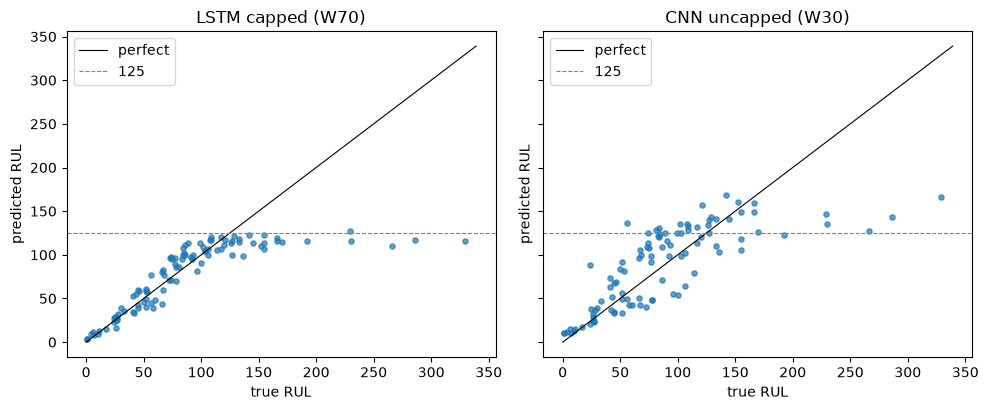

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharex=True, sharey=True)
for ax, p, title in ((axes[0], val_lc[0], "LSTM capped (W70)"), (axes[1], val_cu[0], "CNN uncapped (W30)")):
    ax.scatter(y_val, p, s=14, alpha=0.7)
    lim = [0, max(y_val.max(), p.max()) + 10]
    ax.plot(lim, lim, color="black", linewidth=0.8, label="perfect")
    ax.axhline(LATE, color="grey", linestyle="--", linewidth=0.8, label="125")
    ax.set_title(title); ax.set_xlabel("true RUL"); ax.set_ylabel("predicted RUL"); ax.legend()
plt.tight_layout(); plt.show()

## 8. Which model is best? (validation, 5 seeds)

Every model scored with the same function. Gradient boosting (Phase 1, a single run) is the bar to beat. Rule: lowest overall **RMSE** wins; **late RMSE** decides near-failure accuracy; a gap smaller than the seed spread is a tie.

In [9]:
def from_file(path):
    f = pd.read_csv(path)
    return f[[c for c in f.columns if c.startswith("seed_")]].to_numpy().T

gb = pd.read_csv(f"{RESULTS}/val_predictions_trees.csv")["gradient_boosting"].to_numpy()[None, :]
all_models = {
    "Gradient boosting (Phase 1)": gb,
    "LSTM uncapped": from_file(f"{RESULTS}/val_predictions_lstm_uncapped.csv"),
    "LSTM capped": val_lc,
    "CNN uncapped": val_cu,
    "CNN capped": val_cc,
}
compare = pd.DataFrame({k: summarise_full(v) for k, v in all_models.items()}).T
compare = compare[["mae", "rmse", "rmse_std", "r2", "early_rmse", "late_rmse", "late_precision", "late_recall"]]
compare.round(3).to_csv(f"{RESULTS}/metrics_validation_srijan_comparison.csv")
print("lowest overall RMSE :", compare["rmse"].idxmin())
print("lowest late RMSE    :", compare["late_rmse"].idxmin())
compare.round(2)

lowest overall RMSE : LSTM uncapped
lowest late RMSE    : LSTM capped


,mae,rmse,rmse_std,r2,early_rmse,late_rmse,late_precision,late_recall
Gradient boosting (Phase 1),26.12,40.17,0.00,0.56,69.54,26.54,0.88,0.86
LSTM uncapped,23.48,36.28,2.81,0.64,62.96,23.78,0.93,0.86
LSTM capped,21.25,39.79,0.53,0.57,81.35,12.72,0.79,1.00
CNN uncapped,25.43,40.14,1.52,0.56,72.75,23.78,0.90,0.93
CNN capped,23.66,42.03,1.01,0.52,84.99,15.02,0.80,0.99


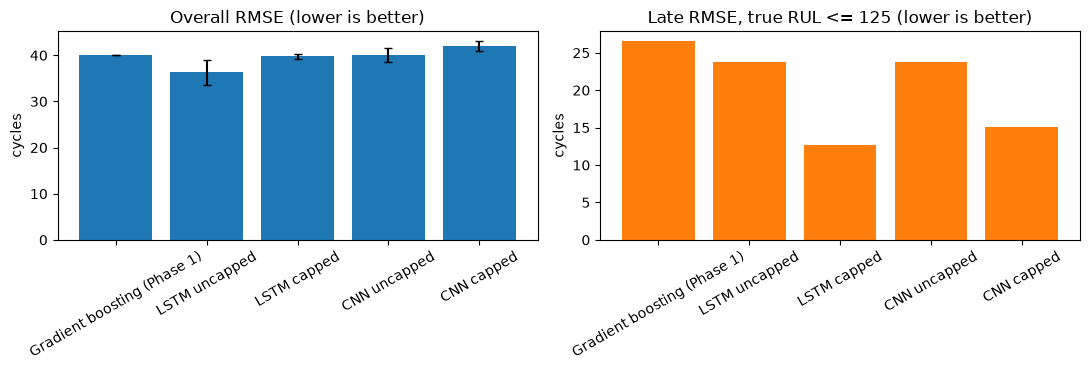

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
order = compare.index
axes[0].bar(order, compare["rmse"], yerr=compare["rmse_std"], capsize=3)
axes[0].set_title("Overall RMSE (lower is better)")
axes[1].bar(order, compare["late_rmse"], color="tab:orange")
axes[1].set_title("Late RMSE, true RUL <= 125 (lower is better)")
for ax in axes:
    ax.set_ylabel("cycles"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

## 9. Findings

Validation, 5 seeds (ladder: 3 seeds). Numbers come from `results/`.

1. **A longer window helps near failure.** Capped LSTM late RMSE: 15.69 (W = 30) → 13.95 (W = 50) → 12.23 (W = 70). Near failure, the shape of the decline over 70 cycles is informative.
2. **Capping halves the near-failure error.** Late RMSE: capped LSTM 12.72, uncapped LSTM 23.78, gradient boosting (Phase 1) 26.54.
3. **The price: healthy engines.** The capped model never saw a target above 125, so its early RMSE is 81.35 (uncapped LSTM 62.96) and its overall RMSE is worse (39.79 vs 36.28). The scatter flattens at 125. A capped model alone is not enough; this is why the final model is a two-stage hybrid.
4. **Memory ladder: gates help, the LSTM is best.** Capped late RMSE: RNN 17.39 → GRU 13.38 → LSTM 12.47. Uncapped overall RMSE: RNN 41.24 → GRU 35.97 → LSTM 34.28. GRU is close: on uncapped late RMSE it is slightly better (22.43 vs 23.56), a gap inside the seed noise. The settings were tuned for the LSTM, so a GRU-specific search could narrow the gap.
5. **The CNN loses to the LSTM.** Capped: late RMSE 15.02 vs 12.72. Uncapped: overall RMSE 40.14 vs 36.28 (the same as gradient boosting, 40.17). It has 5 to 26 times more weights (270,945 / 598,625 vs 55,873 / 22,593), almost all in the flatten → dense layer, fitted on the same 64 engines.
6. **Precision and recall must be read together.** The capped LSTM has late recall 0.997 but precision 0.786: it calls nearly everything "close to failure" because it almost never predicts above 125.

**Best model.** No single model wins both jobs. **LSTM capped** is best near failure (late RMSE 12.72). **LSTM uncapped** is best overall (RMSE 36.28 ± 2.81, though with the widest seed spread). Both LSTMs beat the CNN, RNN, GRU and gradient boosting on their own job, so the LSTM is the architecture we keep, and the two-stage hybrid combines the two LSTMs.

## 10. Why we used each model, and viva notes

| Model | Exact reason it is used | Verdict |
| --- | --- | --- |
| **Capped LSTM** | Near failure the true RUL is exact, so a model trained on RUL capped at 125 spends all its effort on the part where sensors change. The LSTM memory lets it read the decline over 70 cycles, which the Phase 1 features (10 cycles) cannot. | Best near failure (late RMSE 12.72). Fails on healthy engines, so it is the near-failure expert in the hybrid. |
| **Uncapped LSTM** (Akhil) | Trained on the true RUL, so it can say 200 or 300 for healthy engines. | Best overall RMSE; noisy near failure. |
| **1D CNN** | A different architecture family, so the result is not one lucky model. Filters slide along time over 14 sensor channels and detect local patterns ("sensor 4 rising over 5 cycles"). It is fast and has no step-by-step recurrence. Convolution works on any grid, not only images. | Loses to the LSTM: each filter sees only 11 cycles and the flatten layer has up to 598,625 weights for 64 fitting engines. |
| **Plain RNN** | The control with no gates. It shows what the gates add. | Worst: early information fades over 30 to 70 steps. |
| **GRU** | The lighter gated model (2 gates, no separate memory cell, about 23% fewer weights than the LSTM). | Close to the LSTM, slightly behind on overall RMSE and capped late RMSE. |
| **LSTM** | 3 gates plus a separate memory cell: it decides what to forget, add and output, so it keeps a slow drift over many cycles. | Chosen. |

### Viva questions

**Why a CNN when CNNs are for images?**
A CNN is a local-pattern detector with shared weights, not an image model. An image is a 2D grid with 3 colour channels; our window is a 1D grid (time) with 14 channels (sensors). Filters slide along time only, because neighbouring cycles are related but the order of sensor columns means nothing. CNNs are used on C-MAPSS in published work (Babu et al., 2016; Li et al., 2018). We used it as a second architecture family. It lost on validation.

**Why did the CNN lose?**
It has 5 to 26 times more weights than the LSTM, almost all in the flatten → dense layer, and only 64 engines to fit them. Each conv filter sees only 11 cycles. Global average pooling did even worse because it forgets *when* a pattern happened.

**Why a plain RNN at all?**
It is the no-gates control. It forgets early cycles because its memory is overwritten at every step (vanishing gradient). Our result (RNN worst, GRU close, LSTM best) is consistent with that, but we did not measure gradients, so we do not claim proof.

**GRU vs LSTM?**
The GRU merges the memory into the hidden state and uses 2 gates, so it is lighter and nearly as good. The LSTM wins on uncapped overall RMSE (34.28 vs 35.97) and on capped late RMSE (12.47 vs 13.38). On uncapped late RMSE the GRU is slightly better, inside the seed noise. The settings were tuned for the LSTM.

**Why is the LSTM the right choice here?**
Its separate memory cell and three gates keep information over 30 to 70 cycles. It gave the lowest error in both jobs (capped near failure, uncapped overall), and it is small (22,593 weights for the capped model).

**Isn't capping cheating?**
No. Only the training target is capped. Every score uses the true RUL, so the misses on healthy engines are counted.

**Why can't the capped model predict 300?**
It never saw a target above 125.

**Why does a longer window help the capped model?**
Near failure, the shape of the decline over 70 cycles is informative. For healthy engines nothing has declined yet, so more history is just noise.

**Why lr 0.003 for the capped LSTM?**
It had the best late RMSE on validation. The top settings differ by about one cycle, so we took the simplest good one.

**Which metric picks the best model?**
Validation RMSE for overall, late RMSE for near failure. A gap smaller than the seed spread is a tie. Test is scored once, in notebook 10, and never changes the choice.

**Why precision and recall in a regression project?**
The maintenance decision is yes or no ("close to failure?"). Recall measures the dangerous miss (a dying engine called healthy); precision measures wasted maintenance. They do not rank the models, and recall alone can be gamed (capped LSTM recall 0.997, precision 0.786).